In [78]:
# 1. Install system dependencies for Chromium
!apt-get update
!apt-get install -y chromium-chromedriver

# 2. Install python packages directly into the active kernel environment
!pip install selenium webdriver-manager --upgrade -q

# 3. Verify the installation worked within this kernel session
try:
    import selenium
    print("SUCCESS: Selenium is successfully installed and registered!")
except ImportError as e:
    print(f"FAIL: Selenium installation failed: {e}")

Hit:1 https://cli.github.com/packages stable InRelease
Hit:2 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:3 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:5 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:6 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
chromium-chromedriver is already the newest version (2:1snap1-0ubuntu2).
0 upgraded, 0 newly installed, 0 to remove and 24 not upgraded.
SUCCESS: Selenium is successfully

### Headless Chrome Options for Google Colab
To run Selenium inside Colab's headless cloud runtime, you need to pass specific arguments to your Chrome webdriver configuration:
1. `--headless` (Runs without GUI)
2. `--no-sandbox` (Required inside container environments like Colab)
3. `--disable-dev-shm-usage` (Prevents crashes due to limited shared memory)

In [79]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from selenium import webdriver
from selenium.webdriver.chrome.service import Service
from webdriver_manager.chrome import ChromeDriverManager
import time
import io
from selenium.webdriver.common.by import By



def load_season(season_str, season_year):
    urls = {
        "E0": f"https://www.football-data.co.uk/mmz4281/{season_str}/E0.csv",
        "E1": f"https://www.football-data.co.uk/mmz4281/{season_str}/E1.csv",
        "E2": f"https://www.football-data.co.uk/mmz4281/{season_str}/E2.csv",
    }

    dfs = []
    for div, url in urls.items():
        try:
            df = pd.read_csv(url).copy()
            df["season"] = season_year
            dfs.append(df)
            print(f"Loaded {div} {season_year}: {len(df)} rows")

        except Exception as e:
            print(f"Skipping {div} {season_year}: {e}")

    return pd.concat(dfs, ignore_index=True)

# Load multiple seasons
seasons = [
    ("2324", "2023/24"),
    ("2425", "2024/25"),
    ("2526", "2025/26"),
    ("2627", "2026/27")
]

all_data = pd.concat([load_season(s, y) for s, y in seasons], ignore_index=True)

# Keep only the columns we want
keep_cols = [
    "Div", "Date", "Time", "HomeTeam", "AwayTeam", "season",
    "FTHG", "FTAG", "FTR", "HTHG", "HTAG", "HTR",
    "HS", "AS", "HST", "AST", "HC", "AC", "HF", "AF", "HY", "AY", "HR", "AR",
    "AvgH", "AvgD", "AvgA", "PSH", "PSD", "PSA", "Avg>2.5", "Avg<2.5"
]

df = all_data[keep_cols].copy()
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)
df = df.sort_values("Date").reset_index(drop=True)

# Drop rows with no result yet (future fixtures)
df = df.dropna(subset=["FTHG", "FTAG"])

print(df.shape)
print(df.isnull().sum())
print(df.head())

df.to_csv("football_data.csv", index=False)


Loaded E0 2023/24: 380 rows
Loaded E1 2023/24: 552 rows
Loaded E2 2023/24: 552 rows
Loaded E0 2024/25: 380 rows
Loaded E1 2024/25: 552 rows
Loaded E2 2024/25: 552 rows
Loaded E0 2025/26: 380 rows
Loaded E1 2025/26: 552 rows
Loaded E2 2025/26: 552 rows
Loaded E0 2026/27: 50 rows
Loaded E1 2026/27: 95 rows
Loaded E2 2026/27: 90 rows
(4687, 32)
Div            0
Date           0
Time           0
HomeTeam       0
AwayTeam       0
season         0
FTHG           0
FTAG           0
FTR            0
HTHG           0
HTAG           0
HTR            0
HS             0
AS             0
HST            0
AST            0
HC             0
AC             0
HF             0
AF             0
HY             0
AY             0
HR             0
AR             0
AvgH           0
AvgD           0
AvgA           0
PSH         1084
PSD         1084
PSA         1084
Avg>2.5        0
Avg<2.5        0
dtype: int64
  Div       Date   Time        HomeTeam     AwayTeam   season  FTHG  FTAG FTR  \
0  E1 2023-08-04  

In [80]:
# import pandas as pd
# import requests
# import io

# # 1. Get a list of all unique teams in your fixture dataset
# my_fixture_teams = set(df['HomeTeam'].unique())

# # 2. Disguise our request as a standard Chrome web browser
# headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36'}
# url = 'http://api.clubelo.com/2023-01-01'

# # 3. Download the data using requests, then feed the raw text into pandas
# response = requests.get(url, headers=headers)
# print(f"Club Elo API response status code: {response.status_code}")
# print(f"Club Elo API response text length: {len(response.text)}")
# print(f"Club Elo API response (first 200 chars):\n{response.text[:200]}")
# daily_elo = pd.read_csv(io.StringIO(response.text))

# # 4. Filter for English teams and turn them into a set
# clubelo_english_teams = set(daily_elo[daily_elo['Country'] == 'ENG']['Club'].unique())

# # 5. Find the spelling mismatches
# mismatched_teams = my_fixture_teams - clubelo_english_teams

# print("Teams I need to add to my dictionary:")
# for team:
#     print(team)

In [81]:
# import soccerdata as sd

# # Initialize the ClubElo scraper
# elo = sd.ClubElo()

# # Pull the complete historical DataFrame for all teams
# elo_df = elo.read_by_date("2023-01-01")
# print(elo_df.head())

In [82]:
# import requests

# url = 'http://api.clubelo.com/2023-01-01'
# headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36'}

# response = requests.get(url, headers=headers)

# print(f"Status Code: {response.status_code}")
# print(f"Raw Text Length: {len(response.text)}")
# print(f"First 100 characters: {response.text[:100]}")

In [83]:
# #loading global rankings
# # 1. Grab every home team and away team from your training data
# all_teams = pd.concat([df['HomeTeam'], df['AwayTeam']])

# # 2. Drop the duplicates to get a clean list of just the ~70-80 English clubs
# unique_english_clubs = all_teams.unique()

# # 3. Only pull the historical API data for those specific clubs
# for team in unique_english_clubs:
#     # Remember to use your TEAM_NAME_MAP here if the spellings differ!
#     url = f'http://api.clubelo.com/{team}'
#     # ... download and save the data ...


In [84]:
print(df.groupby(["season", "Div"]).size())

season   Div
2023/24  E0     380
         E1     552
         E2     552
2024/25  E0     380
         E1     552
         E2     552
2025/26  E0     380
         E1     552
         E2     552
2026/27  E0      50
         E1      95
         E2      90
dtype: int64


In [85]:
# # All seasons
# seasons = [
#     # Championship
#     ("2026/27", "Championship", "https://www.whoscored.com/regions/252/tournaments/7/seasons/11184/england-championship"),
#     ("2025/26", "Championship", "https://www.whoscored.com/regions/252/tournaments/7/seasons/10784/stages/24580/teamstatistics/england-championship-2025-2026"),
#     ("2024/25", "Championship", "https://www.whoscored.com/regions/252/tournaments/7/seasons/10343/stages/23427/teamstatistics/england-championship-2024-2025"),
#     ("2023/24", "Championship", "https://www.whoscored.com/regions/252/tournaments/7/seasons/9622/stages/23160/teamstatistics/england-championship-2023-2024"),

#     # Premier League
#     ("2026/27", "PL", "https://www.whoscored.com/regions/252/tournaments/2/england-premier-league"),
#     ("2025/26", "PL", "https://www.whoscored.com/regions/252/tournaments/2/seasons/10743/stages/24533/teamstatistics/england-premier-league-2025-2026"),
#     ("2024/25", "PL", "https://www.whoscored.com/regions/252/tournaments/2/seasons/10316/stages/23400/teamstatistics/england-premier-league-2024-2025"),
#     ("2023/24", "PL", "https://www.whoscored.com/regions/252/tournaments/2/seasons/9618/stages/22076/teamstatistics/england-premier-league-2023-2024"),

#     # League One
#     ("2026/27", "L1", "https://www.whoscored.com/regions/252/tournaments/8/seasons/11185/england-league-one"),
#     ("2025/26", "L1", "https://www.whoscored.com/regions/252/tournaments/8/seasons/10785/stages/24581/teamstatistics/england-league-one-2025-2026"),
#     ("2024/25", "L1", "https://www.whoscored.com/regions/252/tournaments/8/seasons/10342/stages/24356/teamstatistics/england-league-one-2024-2025"),
#     ("2023/24", "L1", "https://www.whoscored.com/regions/252/tournaments/8/seasons/9623/stages/22081/teamstatistics/england-league-one-2023-2024"),
# ]

# def scrape_whoscored(driver, season, competition, url):
#     driver.get(url)
#     time.sleep(6)

#     tables = pd.read_html(io.StringIO(driver.page_source))
#     summary = tables[0].copy()

#     # Click passing tab
#     try:
#         tab = driver.find_element(By.CSS_SELECTOR, "a[href*='stage-passes']")
#         driver.execute_script("arguments[0].click();", tab)
#         time.sleep(4)
#         tables_passing = pd.read_html(io.StringIO(driver.page_source))
#         passing = tables_passing[2].copy() if len(tables_passing) > 2 and not tables_passing[2].empty else None
#     except Exception as e:
#         print(f"Could not get passing tab for {competition} {season}: {e}")
#         passing = None

#     # Clean team names
#     summary["Team"] = summary["Team"].str.replace(r'\\d+\\.\\s*', '', regex=True)
#     summary["season"] = season
#     summary["competition"] = competition

#     if passing is not None and not passing.empty:
#         passing["Team"] = passing["Team"].str.replace(r'\\d+\\.\\s*', '', regex=True)
#         if "R" in passing.columns:
#             passing = passing.drop(columns=["R"])
#         merged = summary.merge(passing, on="Team", how="left")
#     else:
#         merged = summary

#     return merged

# driver = webdriver.Chrome(service=Service(ChromeDriverManager().install()))

# all_whoscored = []
# for season, competition, url in seasons:
#     print(f"Scraping {competition} {season}...")
#     temp = scrape_whoscored(driver, season, competition, url)
#     all_whoscored.append(temp)
#     print(f"  Got {len(temp)} teams")

# driver.quit()

# whoscored_df = pd.concat(all_whoscored, ignore_index=True)
# print(whoscored_df.shape)
# print(whoscored_df.columns.tolist())
# whoscored_df.to_csv("whoscored_data.csv", index=False)

In [86]:
# # Get home stats per team
# home = df.groupby(["HomeTeam", "season", "Div"]).agg(
#     home_games=("FTHG", "count"),
#     home_goals_scored=("FTHG", "mean"),
#     home_goals_conceded=("FTAG", "mean"),
#     home_shots=("HS", "mean"),
#     home_shots_target=("HST", "mean"),
#     home_corners=("HC", "mean"),
#     home_fouls=("HF", "mean"),
#     home_yellows=("HY", "mean")
# ).reset_index().rename(columns={"HomeTeam": "team"})

# # Get away stats per team
# away = df.groupby(["AwayTeam", "season", "Div"]).agg(
#     away_games=("FTAG", "count"),
#     away_goals_scored=("FTAG", "mean"),
#     away_goals_conceded=("FTHG", "mean"),
#     away_shots=("AS", "mean"),
#     away_shots_target=("AST", "mean"),
#     away_corners=("AC", "mean"),
#     away_fouls=("AF", "mean"),
#     away_yellows=("AY", "mean")
# ).reset_index().rename(columns={"AwayTeam": "team"})

# # Merge and average home+away into one profile per team
# team_stats = home.merge(away, on=["team", "season", "Div"])

# team_stats["goals_scored"] = (team_stats["home_goals_scored"] + team_stats["away_goals_scored"]) / 2
# team_stats["goals_conceded"] = (team_stats["home_goals_conceded"] + team_stats["away_goals_conceded"]) / 2
# team_stats["shots"] = (team_stats["home_shots"] + team_stats["away_shots"]) / 2
# team_stats["shots_on_target"] = (team_stats["home_shots_target"] + team_stats["away_shots_target"]) / 2
# team_stats["corners"] = (team_stats["home_corners"] + team_stats["away_corners"]) / 2
# team_stats["fouls"] = (team_stats["home_fouls"] + team_stats["away_fouls"]) / 2
# team_stats["yellows"] = (team_stats["home_yellows"] + team_stats["away_yellows"]) / 2

# # Keep only what we need
# cluster_features = team_stats[["team", "season", "Div", "goals_scored", "goals_conceded",
#                                 "shots", "shots_on_target", "corners", "fouls", "yellows"]]

# print(cluster_features.head(20))
# print(cluster_features.shape)

In [87]:
# print(cluster_features.columns.tolist())


In [88]:
# name_map = {
#     'Bristol Rvs': 'Bristol Rovers',
#     'Cambridge': 'Cambridge United',
#     'Crawley Town': 'Crawley Town',
#     'Fleetwood Town': 'Fleetwood Town',
#     'Lincoln': 'Lincoln City',
#     'Man City': 'Manchester City',
#     'Man United': 'Manchester United',
#     "Nott'm Forest": 'Nottingham Forest',
#     'Peterboro': 'Peterborough',
#     'QPR': 'Queens Park Rangers',
#     'Sheffield Weds': 'Sheffield Wednesday',
#     'Stockport': 'Stockport County',
#     'West Brom': 'West Bromwich Albion'
# }

# cluster_features["team"] = cluster_features["team"].replace(name_map)


# cluster_features = cluster_features.merge(
#     whoscored_df[["Team", "season", "Possession%", "Pass%", "Short Passes pg", "Long Balls pg"]],
#     left_on=["team", "season"],
#     right_on=["Team", "season"],
#     how="left"
# ).drop(columns=["Team"])
# cluster_features.head(20)
# print(cluster_features.columns.tolist())


In [89]:
# train = cluster_features[cluster_features["season"] != "2025/26"].copy()
# test = cluster_features[cluster_features["season"] == "2025/26"].copy()

In [90]:
# # Scale the features first — important so goals don't dominate over fouls
# features = ["goals_scored", "goals_conceded", "shots", "shots_on_target", "corners", "fouls", "yellows",
#             "Possession%", "Pass%", "Short Passes pg", "Long Balls pg"]
# X = train[features].dropna()
# scaler = StandardScaler()
# X_scaled = scaler.fit_transform(X)


# # ── Elbow method ──────────────────────────────────────────────────
# # The Elbow Method is a heuristic used to find the optimal number of clusters (k).
# # It plots the Within-Cluster Sum of Squares (Inertia) against a range of k values.
# # The goal is to find the "elbow point"—the point where adding another cluster
# # yields significantly diminishing returns in reducing inertia.


# # --- 1. Setting Up the Evaluation Variables ---
# # Initialize an empty list to store the calculated inertia score for each model setup.
# inertias = []

# # Define the search space: test everything from 1 single global group up to 10 distinct clusters.
# k_range  = range(1, 11)


# # --- 2. Iterative Optimization Loop ---
# # Run the clustering algorithm repeatedly for every k configuration in our range.
# for k in k_range:
#     # Instantiate the K-Means engine for the current value of k.
#     # 'n_init=10' ensures stable, optimal centroid initializations on each loop.
#     m = KMeans(n_clusters=k, random_state=42, n_init=10)

#     # Train the model on the pre-scaled feature matrix.
#     m.fit(X_scaled)

#     # Extract the resulting .inertia_ metric (Within-Cluster Sum of Squares)
#     # and append it to our tracking array list.
#     inertias.append(m.inertia_)


# # --- 3. Plotting the Elbow Curve ---
# # Establish a clean layout canvas measuring 7 inches wide by 4 inches tall.
# plt.figure(figsize=(7, 4))

# # Plot k values on the X-axis and their matching inertia scores on the Y-axis.
# # 'o-' creates a solid line with explicit circle markers highlighting each data point.
# plt.plot(k_range, inertias, 'o-', color='steelblue', linewidth=2)

# # Draw a vertical reference line to pinpoint the "elbow bend" inflection point.
# # For this specific dataset, k=4 is highlighted as the mathematically optimal cluster split.


# # --- 4. Chart Labeling & Aesthetics ---
# # Add contextual axis labels to make the visualization easily readable.
# plt.xlabel('Number of clusters  k')
# plt.ylabel('Inertia (WCSS)')

# # Set the overarching chart title.
# plt.title('Elbow Method')

# # Automatically adjust the padding around the figure to prevent label clipping.
# plt.tight_layout()

# # Render the final interactive canvas figure window on screen.
# plt.show()

In [91]:
# ── Silhouette score for each k ───────────────────────────────────
# The Silhouette Score evaluates the quality of clustering configurations.
# It measures how similar an object is to its own cluster (cohesion) compared
# to other neighboring clusters (separation).
# The score ranges from -1.0 to +1.0:
#   * Near +1.0: Data points are far away from neighboring clusters (highly isolated).
#   * Near  0.0: Data points sit right on the decision boundary between two clusters.
#   * Near -1.0: Data points are likely assigned to the wrong cluster.


# # --- 1. Setting Up Evaluation Variables ---
# # Initialize an empty list to track the average silhouette coefficient for each model.
# sil_scores = []

# # CRUCIAL STEP: The silhouette score requires calculating distances between separate groups.
# # Therefore, it cannot be evaluated for k=1 (a single global cluster has no neighbors).
# # We begin testing from 2 distinct clusters up to 10 clusters.
# k_range2   = range(2, 11)


# --- 2. Iterative Group Optimization & Evaluation Loop ---
# Run the clustering algorithm repeatedly for each k in our specified domain range.
# for k in k_range2:
#     # Instantiate the K-Means engine for the current iteration's cluster count.
#     m      = KMeans(n_clusters=k, random_state=42, n_init=10)

#     # .fit_predict(X) trains the model and immediately outputs the resulting array
#     # of cluster assignment integer labels (e.g., [0, 1, 0, 2, ...]).
#     labels = m.fit_predict(X_scaled)

#     # Compute the mean silhouette coefficient across all individual data points.
#     # It takes the full normalized features array and the matching predicted labels.
#     s      = silhouette_score(X_scaled, labels)

#     # Store the calculated score inside our tracking list array.
#     sil_scores.append(s)

#     # Neatly output the real-time calculated score metrics.
#     print(f'k={k:2d}   silhouette = {s:.3f}')


# # --- 3. Programmatically Extracting the Optimal Configuration ---
# # Look up the index position containing the highest metric value within our results list,
# # then match that index index against our cluster range list to grab the optimal 'k' integer value.
# best_k = list(k_range2)[sil_scores.index(max(sil_scores))]
# print(f'\n→ Best k by silhouette: {best_k}')


# # --- 4. Plotting the Silhouette Metric Distribution Curve ---
# # Establish a clean layout canvas measuring 7 inches wide by 4 inches tall.
# plt.figure(figsize=(7, 4))

# # Plot the test k choices on the X-axis against their calculated silhouette coefficients on the Y-axis.
# # 's-' connects data points with a solid line highlighted by explicit square markers.
# plt.plot(list(k_range2), sil_scores, 's-', color='seagreen', linewidth=2)

# # Draw a vertical reference line precisely at the peak coordinate position to emphasize the optimal model setup.
# plt.axvline(x=best_k, color='tomato', linestyle='--', linewidth=1.5,
#             label=f'Best k={best_k}')


# # --- 5. Chart Labeling & Aesthetics ---
# # Add descriptive labels to provide context for coordinates.
# plt.xlabel('Number of clusters  k')
# plt.ylabel('Silhouette score')

# # Set the main visualization graph title.
# plt.title('Silhouette Score vs k')

# # Draw the interactive legend bounding box mapping our vertical line 'label' text properties.
# plt.legend()

# # Automatically adjust padding to eliminate clipped outer text elements.
# plt.tight_layout()

# # Render the final figure visualization panel on the screen.
# plt.show()

In [92]:
# went with 4 as meaningful but may not be clear-cut categories, come back to add passes and possession stats which are likely to help
# km = KMeans(n_clusters=2, random_state=42, n_init=10)
# km.fit(X_scaled)


# # --- 4. Evaluating Mathematical Training Output Diagnostics ---
# # Print the unique assignment integer tokens created by the model (0, 1, 2, 3).
# print('Cluster labels:     ', np.unique(km.labels_))

# # Inertia measures the Within-Cluster Sum of Squares (WCSS).
# # It calculates the sum of squared distances from every individual point to its assigned centroid.
# # Lower values mean the data points are tightly packed inside their groups.
# print('Inertia (WCSS):     ', round(km.inertia_, 2))

# # Check the dimensions of the final group coordinate matrix.
# # Shape is (4, 2) because we have 4 clusters tracked across a 2-dimensional feature space.
# print('Cluster centres shape:', km.cluster_centers_.shape)


# # --- 5. Visualizing the Segmented Clusters and Centroids ---
# # Create a standard layout canvas measuring 7x5 inches.
# plt.figure(figsize=(7, 5))

# # Layer 1: Plot the raw data coordinate points.
# # - 'c=km.labels_': Color-codes each dot according to its newly assigned K-Means cluster index.
# # - 'cmap='tab10'': Uses a discrete categorical color palette.
# plt.scatter(X_scaled[:,0], X_scaled[:,1],
#             c=km.labels_, cmap='tab10', s=30, alpha=0.7)

# # Layer 2: Overlay the final calculated group anchor centroids on top.
# # - 'marker='X'': Changes the shape parameter to a distinct cross.
# # - 's=200': Increases the marker scale dramatically so they stand out.
# # - 'zorder=5': Guarantees the centroid crosses sit cleanly on the top visual layer.
# plt.scatter(km.cluster_centers_[:,0], km.cluster_centers_[:,1],
#             c='black', marker='X', s=200, label='Centroids', zorder=5)

# # Add title, legend markers, clean margins, and display.
# plt.title('K-Means Clustering  (k=4)')
# plt.legend()
# plt.tight_layout()
# plt.show()
# train.loc[X.index, "cluster"] = km.labels_

# print(train.groupby("cluster")[features].mean().round(2))

# cluster_labels = train.loc[X.index, ["team", "season", "cluster"]].copy()

In [93]:
# print(train[train["team"].isin(["Norwich", "Ipswich"])][["team", "season", "cluster"]])

In [94]:
# print(train[train["cluster"].isna()][["team", "season", "Div"]])

In [95]:
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Sort all matches by date first
df_sorted = df.sort_values("Date").reset_index(drop=True)

name_map = {
    'Bristol Rvs': 'Bristol Rovers', 'Cambridge': 'Cambridge United',
    'Lincoln': 'Lincoln City', 'Man City': 'Manchester City',
    'Man United': 'Manchester United', "Nott'm Forest": 'Nottingham Forest',
    'Peterboro': 'Peterborough', 'QPR': 'Queens Park Rangers',
    'Sheffield Weds': 'Sheffield Wednesday', 'Stockport': 'Stockport County',
    'West Brom': 'West Bromwich Albion'
}

df_sorted["HomeTeam"] = df_sorted["HomeTeam"].replace(name_map)
df_sorted["AwayTeam"] = df_sorted["AwayTeam"].replace(name_map)

# ── Rolling stats for HOME team ───────────────────────────────────────────
def rolling_team_stats(df, team_col, goals_for_col, goals_against_col, shots_col, prefix, n=5):
    """Calculate rolling averages for a team across all their matches"""
    results = []

    for team in df[team_col].unique():
        team_matches = df[df[team_col] == team].copy()
        team_matches[f"{prefix}_goals_scored_avg"] = (
            team_matches[goals_for_col].shift(1).ewm(span=n, min_periods=1).mean()
        )
        team_matches[f"{prefix}_goals_conceded_avg"] = (
            team_matches[goals_against_col].shift(1).ewm(span=n, min_periods=1).mean()
        )
        team_matches[f"{prefix}_shots_avg"] = (
            team_matches[shots_col].shift(1).ewm(span=n, min_periods=1).mean()
        )
        team_matches[f"{prefix}_std_goals_scored"] = (
            team_matches[goals_for_col].shift(1).rolling(n, min_periods=1).std()
        )
        team_matches[f"{prefix}_std_goals_conceded"] = (
            team_matches[goals_against_col].shift(1).rolling(n, min_periods=1).std()
        )
        results.append(team_matches)

    return pd.concat(results).sort_values("Date")

# Home team rolling stats
home_rolling = rolling_team_stats(
    df_sorted, "HomeTeam", "FTHG", "FTAG", "HS", "home"
)[["Date", "HomeTeam", "home_goals_scored_avg", "home_goals_conceded_avg", "home_shots_avg", "home_std_goals_scored", "home_std_goals_conceded"]]

# Away team rolling stats
away_rolling = rolling_team_stats(
    df_sorted, "AwayTeam", "FTAG", "FTHG", "AS", "away"
)[["Date", "AwayTeam", "away_goals_scored_avg", "away_goals_conceded_avg", "away_shots_avg", "away_std_goals_scored", "away_std_goals_conceded"]]

# Home team long-window rolling stats (baseline for mean-regression signal)
home_rolling_long = rolling_team_stats(
    df_sorted, "HomeTeam", "FTHG", "FTAG", "HS", "home_long", n=8
)[["Date", "HomeTeam", "home_long_goals_scored_avg", "home_long_goals_conceded_avg", "home_long_shots_avg"]]

# Away team long-window rolling stats
away_rolling_long = rolling_team_stats(
    df_sorted, "AwayTeam", "FTAG", "FTHG", "AS", "away_long", n=8
)[["Date", "AwayTeam", "away_long_goals_scored_avg", "away_long_goals_conceded_avg", "away_long_shots_avg"]]





# ── Join rolling stats onto main dataframe ────────────────────────────────
df_model = df_sorted.merge(home_rolling, on=["Date", "HomeTeam"], how="left")
df_model = df_model.merge(away_rolling, on=["Date", "AwayTeam"], how="left")
df_model = df_model.merge(home_rolling_long, on=["Date", "HomeTeam"], how="left")
df_model = df_model.merge(away_rolling_long, on=["Date", "AwayTeam"], how="left")

name_map = {
    'Bristol Rvs': 'Bristol Rovers', 'Cambridge': 'Cambridge United',
    'Lincoln': 'Lincoln City', 'Man City': 'Manchester City',
    'Man United': 'Manchester United', "Nott'm Forest": 'Nottingham Forest',
    'Peterboro': 'Peterborough', 'QPR': 'Queens Park Rangers',
    'Sheffield Weds': 'Sheffield Wednesday', 'Stockport': 'Stockport County',
    'West Brom': 'West Bromwich Albion'
}

df_model["HomeTeam"] = df_model["HomeTeam"].replace(name_map)
df_model["AwayTeam"] = df_model["AwayTeam"].replace(name_map)

print(df_model.shape)




#adding mean regression features
df_model["home_goals_scored_overperformance"] = df_model["home_goals_scored_avg"] - df_model["home_long_goals_scored_avg"]
df_model["away_goals_scored_overperformance"] = df_model["away_goals_scored_avg"] - df_model["away_long_goals_scored_avg"]
df_model["home_goals_conceded_overperformance"] = df_model["home_goals_conceded_avg"] - df_model["home_long_goals_conceded_avg"]
df_model["away_goals_conceded_overperformance"] = df_model["away_goals_conceded_avg"] - df_model["away_long_goals_conceded_avg"]

# adding the league points and goal difference in here

def get_points_and_gd(row, team):
    if team == row["HomeTeam"]:
        team_goals = row["FTHG"]
        opp_goals = row["FTAG"]
    else:
        team_goals = row["FTAG"]
        opp_goals = row["FTHG"]

    if team_goals > opp_goals:
        points = 3
    elif team_goals == opp_goals:
        points = 1
    else:
        points = 0

    goal_diff = team_goals - opp_goals

    return points, goal_diff

results = []

for season in df_model["season"].unique():

    for team in df_model["HomeTeam"].unique():
        team_matches = df_model[((df_model["HomeTeam"] == team) | (df_model["AwayTeam"] == team)) & (df_model["season"] == season)].sort_values("Date")
        team_matches["team"] = team

        points_list = []
        gd_list = []

        for index, row in team_matches.iterrows():
            points, gd = get_points_and_gd(row, team)
            points_list.append(points)
            gd_list.append(gd)

        team_matches["league_points"] = pd.Series(points_list).cumsum().shift(1).values
        team_matches["league_gd"] = pd.Series(gd_list).cumsum().shift(1).values

        results.append(team_matches)
league_position_df = pd.concat(results)


home_league = league_position_df[league_position_df["team"] == league_position_df["HomeTeam"]]
away_league = league_position_df[league_position_df["team"] == league_position_df["AwayTeam"]]

df_model = df_model.merge(
    home_league[["HomeTeam", "season", "Date", "league_points", "league_gd"]].rename(columns={"league_points": "home_league_points", "league_gd": "home_league_gd"}),
    on=["HomeTeam", "season", "Date"], how="left"
)

df_model = df_model.merge(
    away_league[["AwayTeam", "season", "Date", "league_points", "league_gd"]].rename(columns={"league_points": "away_league_points", "league_gd": "away_league_gd"}),
    on=["AwayTeam", "season", "Date"], how="left"
)

print(df_model.shape)

for col in ["home_league_points", "home_league_gd", "away_league_points", "away_league_gd"]:
    df_model[col] = pd.to_numeric(df_model[col], errors="coerce")



# ── Join cluster labels ───────────────────────────────────────────────────
# df_model = df_model.merge(
#     cluster_labels.rename(columns={"team": "HomeTeam", "cluster": "home_cluster"}),
#     on=["HomeTeam", "season"], how="left"
# )
# df_model = df_model.merge(
#     cluster_labels.rename(columns={"team": "AwayTeam", "cluster": "away_cluster"}),
#     on=["AwayTeam", "season"], how="left"
# )

# ── Rename problem columns ────────────────────────────────────────────────
df_model = df_model.rename(columns={
    "Avg>2.5": "Avg_over_2_5",
    "Avg<2.5": "Avg_under_2_5"
})

# -- add the h2h features
mean_scored = []
mean_conceded = []
has_h2h_history = []

for index, row in df_model.iterrows():
    home_team = row["HomeTeam"]
    away_team = row["AwayTeam"]

    trying = df_model[(df_model["HomeTeam"] == home_team) & (df_model["AwayTeam"] == away_team) & (df_model["Date"] < row["Date"])  | (df_model["AwayTeam"] == home_team) & (df_model["HomeTeam"] == away_team) & (df_model["Date"] < row["Date"]) ].sort_values("Date").iloc[-2:]


    if len(trying) >= 2:
        h2h_scored = np.where(trying["HomeTeam"] == home_team, trying["FTHG"], trying["FTAG"])
        h2h_conceded = np.where(trying["HomeTeam"] == home_team, trying["FTAG"], trying["FTHG"])

        mean_scored.append(h2h_scored.mean())
        mean_conceded.append(h2h_conceded.mean())
        has_h2h_history.append(1)

    elif len(trying) == 1:
        single_row = trying.iloc[0]

        if single_row["HomeTeam"] == home_team:
            h2h_scored = single_row["FTHG"]
            h2h_conceded = single_row["FTAG"]
        else:
            h2h_scored = single_row["FTAG"]
            h2h_conceded = single_row["FTHG"]

        mean_scored.append(h2h_scored)
        mean_conceded.append(h2h_conceded)
        has_h2h_history.append(0)

    else:
        mean_scored.append(0)  # Use home team's average scored if no history
        mean_conceded.append(0) # Use home team's average conceded if no history
        has_h2h_history.append(0)


df_model["h2h_mean_scored"] = mean_scored
df_model["h2h_mean_conceded"] = mean_conceded
df_model["h2h_has_history"] = has_h2h_history

#  --- Creating actual form and home advantage features for the model
# df_model = pd.merge_asof(df_model, away_rolling, left_on="Date", right_on="Date", left_by="HomeTeam", right_by="AwayTeam", direction="backward")
# df_model = pd.merge_asof(df_model, home_rolling, left_on="Date", right_on="Date", left_by="AwayTeam_x", right_by="HomeTeam", direction="backward")

# df_model = df_model.rename(columns={
#     "HomeTeam_x": "HomeTeam",
#     "AwayTeam_x": "AwayTeam",
#     "home_goals_scored_avg_x": "home_goals_scored_avg",
#     "home_goals_conceded_avg_x": "home_goals_conceded_avg",
#     "home_shots_avg_x": "home_shots_avg",
#     "away_goals_scored_avg_x": "away_goals_scored_avg",
#     "away_goals_conceded_avg_x": "away_goals_conceded_avg",
#     "away_shots_avg_x": "away_shots_avg",
#     "away_goals_scored_avg_y": "home_teams_away_form_scored",
#     "away_goals_conceded_avg_y": "home_teams_away_form_conceded",
#     "away_shots_avg_y": "home_teams_away_form_shots",
#     "home_goals_scored_avg_y": "away_teams_home_form_scored",
#     "home_goals_conceded_avg_y": "away_teams_home_form_conceded",
#     "home_shots_avg_y": "away_teams_home_form_shots",
# })

# df_model = df_model.drop(columns=["AwayTeam_y", "HomeTeam_y"])

# df_model["home_teams_home_advantage_scored"] = df_model["home_goals_scored_avg"] - df_model["home_teams_away_form_scored"]
# df_model["away_teams_home_advantage_scored"] = df_model["away_teams_home_form_scored"] - df_model["away_goals_scored_avg"]



# ── Split ─────────────────────────────────────────────────────────────────
train_df = df_model[df_model["season"].isin(["2023/24", "2024/25"])].copy()
test_df  = df_model[df_model["season"] == "2025/26"].copy()
#uncomment the row, when improving this is just for live predictions

# ── Define features ───────────────────────────────────────────────────────
feature_cols = [
    "home_goals_scored_avg", "home_goals_conceded_avg", "home_shots_avg",
    "away_goals_scored_avg", "away_goals_conceded_avg", "away_shots_avg",
    "home_league_points", "home_league_gd", "away_league_points", "away_league_gd",
    "h2h_mean_scored", "h2h_mean_conceded", "h2h_has_history",
    "home_goals_scored_overperformance", "away_goals_scored_overperformance",
    "home_goals_conceded_overperformance", "away_goals_conceded_overperformance",
    #"home_teams_home_advantage_scored", "away_teams_home_advantage_scored"
]
X_train = train_df[feature_cols]
y_train_home = train_df["FTHG"]
y_train_away = train_df["FTAG"]

X_test = test_df[feature_cols]
y_test_home = test_df["FTHG"]
y_test_away = test_df["FTAG"]

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(X_train.isnull().sum())
print(df_model)

(4687, 48)


/tmp/ipykernel_303/2939035375.py:139: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  league_position_df = pd.concat(results)


(4687, 56)
Train: (2968, 17), Test: (1484, 17)
home_goals_scored_avg                  72
home_goals_conceded_avg                72
home_shots_avg                         72
away_goals_scored_avg                  72
away_goals_conceded_avg                72
away_shots_avg                         72
home_league_points                     68
home_league_gd                         68
away_league_points                     68
away_league_gd                         68
h2h_mean_scored                         0
h2h_mean_conceded                       0
h2h_has_history                         0
home_goals_scored_overperformance      72
away_goals_scored_overperformance      72
home_goals_conceded_overperformance    72
away_goals_conceded_overperformance    72
dtype: int64
     Div       Date   Time             HomeTeam        AwayTeam   season  \
0     E1 2023-08-04  20:00  Sheffield Wednesday     Southampton  2023/24   
1     E2 2023-08-05  15:00               Bolton    Lincoln City  2023/24  

In [96]:
model_home = xgb.XGBRegressor(
    objective="count:poisson",
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)
model_home.fit(X_train, y_train_home)

model_away = xgb.XGBRegressor(
    objective="count:poisson",
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)
model_away.fit(X_train, y_train_away)

pred_home = model_home.predict(X_test)
pred_away = model_away.predict(X_test)

print("Home goals MAE:", round(mean_absolute_error(y_test_home, pred_home), 3))
print("Away goals MAE:", round(mean_absolute_error(y_test_away, pred_away), 3))

results = test_df[["HomeTeam", "AwayTeam", "FTHG", "FTAG"]].copy()
results["pred_home"] = pred_home.round(2)
results["pred_away"] = pred_away.round(2)
print(results.head(20))

Home goals MAE: 0.939
Away goals MAE: 0.831
              HomeTeam       AwayTeam  FTHG  FTAG  pred_home  pred_away
2968             Luton  AFC Wimbledon     1     0       0.99       1.04
2969         Rotherham      Port Vale     2     1       1.25       0.88
2970           Cardiff   Peterborough     2     1       1.52       0.98
2971         Blackpool      Stevenage     2     3       1.21       1.14
2972          Bradford        Wycombe     2     1       1.97       1.15
2973            Burton      Mansfield     2     1       1.23       1.40
2974         Doncaster         Exeter     1     0       1.80       1.43
2975      Huddersfield  Leyton Orient     3     0       1.45       1.59
2976      Lincoln City        Reading     2     0       1.66       1.29
2977          Plymouth       Barnsley     1     3       1.13       1.45
2978             Wigan    Northampton     3     1       1.04       1.25
2979  Stockport County         Bolton     2     0       1.31       1.15
2980         Port Va

In [97]:
from scipy.stats import poisson
import numpy as np

def predict_scoreline(home_xg, away_xg, max_goals=6):
    """Generate probability grid for every scoreline"""
    home_probs = [poisson.pmf(i, home_xg) for i in range(max_goals + 1)]
    away_probs = [poisson.pmf(i, away_xg) for i in range(max_goals + 1)]

    # Outer product gives probability of every combination
    grid = np.outer(home_probs, away_probs)
    return grid

# Test on Norwich vs Millwall
grid = predict_scoreline(1.28, 0.79)

print("Scoreline probabilities:")
for h in range(5):
    for a in range(5):
        print(f"  {h}-{a}: {grid[h,a]:.3f}")

print(f"\nMost likely scoreline: {np.unravel_index(grid.argmax(), grid.shape)}")

Scoreline probabilities:
  0-0: 0.126
  0-1: 0.100
  0-2: 0.039
  0-3: 0.010
  0-4: 0.002
  1-0: 0.162
  1-1: 0.128
  1-2: 0.050
  1-3: 0.013
  1-4: 0.003
  2-0: 0.103
  2-1: 0.082
  2-2: 0.032
  2-3: 0.008
  2-4: 0.002
  3-0: 0.044
  3-1: 0.035
  3-2: 0.014
  3-3: 0.004
  3-4: 0.001
  4-0: 0.014
  4-1: 0.011
  4-2: 0.004
  4-3: 0.001
  4-4: 0.000

Most likely scoreline: (np.int64(1), np.int64(0))


In [98]:
print(
    df_model[
        (df_model["HomeTeam"] == "Norwich") |
        (df_model["AwayTeam"] == "Norwich")
    ][["Date", "HomeTeam", "AwayTeam"]]
)

           Date          HomeTeam    AwayTeam
20   2023-08-05           Norwich        Hull
25   2023-08-12       Southampton     Norwich
101  2023-08-20           Norwich    Millwall
113  2023-08-26      Huddersfield     Norwich
140  2023-09-02         Rotherham     Norwich
...         ...               ...         ...
4548 2026-09-01             Stoke     Norwich
4575 2026-09-05  Sheffield United     Norwich
4608 2026-09-09           Norwich  Birmingham
4621 2026-09-12     Middlesbrough     Norwich
4677 2026-09-20           Norwich      Bolton

[146 rows x 3 columns]


In [99]:
# changing h2h and other predictions to be correct
def get_h2h_stats(home_team, away_team, before_date, df_model):

    trying = df_model[
        (df_model["HomeTeam"] == home_team) & (df_model["AwayTeam"] == away_team) & (df_model["Date"] < before_date)
        | (df_model["AwayTeam"] == home_team) & (df_model["HomeTeam"] == away_team) & (df_model["Date"] < before_date)
    ].sort_values("Date").iloc[-2:]

    if len(trying) >= 2:
        h2h_scored = np.where(trying["HomeTeam"] == home_team, trying["FTHG"], trying["FTAG"])
        h2h_conceded = np.where(trying["HomeTeam"] == home_team, trying["FTAG"], trying["FTHG"])

        mean_scored = h2h_scored.mean()
        mean_conceded = h2h_conceded.mean()
        has_h2h_history = 1

    elif len(trying) == 1:
        single_row = trying.iloc[0]

        if single_row["HomeTeam"] == home_team:
            h2h_scored = single_row["FTHG"]
            h2h_conceded = single_row["FTAG"]
        else:
            h2h_scored = single_row["FTAG"]
            h2h_conceded = single_row["FTHG"]

        mean_scored = h2h_scored
        mean_conceded = h2h_conceded
        has_h2h_history = 0

    else:
        mean_scored = 0
        mean_conceded = 0
        has_h2h_history = 0

    return mean_scored, mean_conceded, has_h2h_history

In [100]:
get_h2h_stats("Norwich", "Ipswich", pd.Timestamp("2026-10-05"), df_model)

(np.float64(0.5), np.float64(2.5), 1)

In [101]:
def predict_match(home_team, away_team, season, div, df_model, model_home, model_away, feature_cols, max_goals=6):
    """
    Predict scoreline probabilities for a given match.
    Uses the most recent rolling stats for each team.
    """

    # ── Get most recent stats for home team ──────────────────────────────
    home_stats = df_model[
        (df_model["HomeTeam"] == home_team) |
        (df_model["AwayTeam"] == home_team)
    ].sort_values("Date").iloc[-1]

    away_stats = df_model[
        (df_model["HomeTeam"] == away_team) |
        (df_model["AwayTeam"] == away_team)
    ].sort_values("Date").iloc[-1]

    # # ── Get cluster labels ────────────────────────────────────────────────
    # home_cluster = cluster_labels[cluster_labels["team"] == home_team]["cluster"].values
    # away_cluster = cluster_labels[cluster_labels["team"] == away_team]["cluster"].values
    # home_cluster = home_cluster[-1] if len(home_cluster) > 0 else np.nan
    # away_cluster = away_cluster[-1] if len(away_cluster) > 0 else np.nan

    # ── Build feature row ─────────────────────────────────────────────────
    row = {
        "home_goals_scored_avg":   home_stats["home_goals_scored_avg"],
        "home_goals_conceded_avg": home_stats["home_goals_conceded_avg"],
        "home_shots_avg":          home_stats["home_shots_avg"],
        "away_goals_scored_avg":   away_stats["away_goals_scored_avg"],
        "away_goals_conceded_avg": away_stats["away_goals_conceded_avg"],
        "away_shots_avg":          away_stats["away_shots_avg"],
        "home_league_points":      home_stats["home_league_points"],
        "home_league_gd":          home_stats["home_league_gd"],
        "away_league_points":      away_stats["away_league_points"],
        "away_league_gd":          away_stats["away_league_gd"],
        "h2h_mean_scored":         home_stats["h2h_mean_scored"],
        "h2h_mean_conceded":       home_stats["h2h_mean_conceded"],
        "h2h_has_history":         home_stats["h2h_has_history"],
        "home_goals_scored_overperformance":   home_stats["home_goals_scored_overperformance"],
        "away_goals_scored_overperformance":   away_stats["away_goals_scored_overperformance"],
        "home_goals_conceded_overperformance": home_stats["home_goals_conceded_overperformance"],
        "away_goals_conceded_overperformance": away_stats["away_goals_conceded_overperformance"],
        #"home_teams_home_advantage_scored": home_stats["home_teams_home_advantage_scored"],
        #"away_teams_home_advantage_scored": away_stats["away_teams_home_advantage_scored"]
    }

    X = pd.DataFrame([row])

    # ── Predict xG ────────────────────────────────────────────────────────
    home_xg = model_home.predict(X)[0]
    away_xg = model_away.predict(X)[0]

    # ── Poisson scoreline grid ────────────────────────────────────────────
    grid = predict_scoreline(home_xg, away_xg, max_goals)

    # ── Get top 5 scorelines ──────────────────────────────────────────────
    scorelines = []
    for h in range(max_goals + 1):
        for a in range(max_goals + 1):
            scorelines.append((h, a, grid[h, a]))

    scorelines.sort(key=lambda x: x[2], reverse=True)

    print(f"\n{home_team} vs {away_team}")
    print(f"Predicted xG — Home: {home_xg:.2f}  Away: {away_xg:.2f}")
    print(f"\nTop 5 most likely scorelines:")
    for h, a, prob in scorelines[:5]:
        print(f"  {h}-{a}:  {prob*100:.1f}%")

    # ── Outcome probabilities ─────────────────────────────────────────────
    home_win = sum(grid[h, a] for h in range(max_goals+1) for a in range(max_goals+1) if h > a)
    draw     = sum(grid[h, a] for h in range(max_goals+1) for a in range(max_goals+1) if h == a)
    away_win = sum(grid[h, a] for h in range(max_goals+1) for a in range(max_goals+1) if h < a)

    print(f"\nOutcome probabilities:")
    print(f"  Home win: {home_win*100:.1f}%")
    print(f"  Draw:     {draw*100:.1f}%")
    print(f"  Away win: {away_win*100:.1f}%")

    return scorelines[0][:2]  # return most likely scoreline

# ── Test it ───────────────────────────────────────────────────────────────
predict_match("Crystal Palace", "Ipswich", "2026/27", "E0",
              df_model, model_home, model_away, feature_cols)


Crystal Palace vs Ipswich
Predicted xG — Home: 1.36  Away: 1.07

Top 5 most likely scorelines:
  1-1:  12.8%
  1-0:  11.9%
  0-1:  9.4%
  2-1:  8.7%
  0-0:  8.7%

Outcome probabilities:
  Home win: 43.4%
  Draw:     27.0%
  Away win: 29.5%


(1, 1)

In [102]:
print(
    df_model[df_model["HomeTeam"] == "Norwich"]
    .iloc[-1][["Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG"]]
)
print(
    df_model[df_model["AwayTeam"] == "Norwich"]
    .iloc[-1][["Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG"]]
)

Date        2026-09-20 00:00:00
HomeTeam                Norwich
AwayTeam                 Bolton
FTHG                          3
FTAG                          4
Name: 4677, dtype: object
Date        2026-09-12 00:00:00
HomeTeam          Middlesbrough
AwayTeam                Norwich
FTHG                          4
FTAG                          3
Name: 4621, dtype: object


In [103]:
print(df.groupby(["season", "Div"]).size())

season   Div
2023/24  E0     380
         E1     552
         E2     552
2024/25  E0     380
         E1     552
         E2     552
2025/26  E0     380
         E1     552
         E2     552
2026/27  E0      50
         E1      95
         E2      90
dtype: int64


In [104]:
print(df.groupby(["season", "Div"]).size())

season   Div
2023/24  E0     380
         E1     552
         E2     552
2024/25  E0     380
         E1     552
         E2     552
2025/26  E0     380
         E1     552
         E2     552
2026/27  E0      50
         E1      95
         E2      90
dtype: int64


In [105]:
df_model[df_model["HomeTeam"].str.contains("West", case=False, na=False)]["HomeTeam"].unique()

array(['West Bromwich Albion', 'West Ham'], dtype=object)

In [106]:
print(df_model[df_model["HomeTeam"] == "Norwich"].iloc[-1][["Date", "HomeTeam", "AwayTeam", "AvgH", "AvgD", "AvgA"]])
print(df_model[df_model["AwayTeam"] == "Ipswich"].iloc[-1][["Date", "HomeTeam", "AwayTeam", "AvgH", "AvgD", "AvgA"]])

Date        2026-09-20 00:00:00
HomeTeam                Norwich
AwayTeam                 Bolton
AvgH                       1.52
AvgD                       4.44
AvgA                       5.39
Name: 4677, dtype: object
Date        2026-09-19 00:00:00
HomeTeam                Everton
AwayTeam                Ipswich
AvgH                       1.76
AvgD                       3.79
AvgA                       4.36
Name: 4673, dtype: object


In [107]:
def best_scoreline_from_grid(grid):
    i, j = np.indices(grid.shape)
    p_home = grid[i > j].sum()
    p_draw = grid[i == j].sum()
    p_away = grid[i < j].sum()
    outcome_prob = np.where(i > j, p_home, np.where(i == j, p_draw, p_away))
    expected_points = 2 * grid + outcome_prob
    h, a = np.unravel_index(expected_points.argmax(), expected_points.shape)
    return h, a

In [108]:
def score_predictions(test_df, df_model, model_home, model_away, feature_cols):

    results = []

    for _, match in test_df.iterrows():
        home_team = match["HomeTeam"]
        away_team = match["AwayTeam"]
        actual_home = match["FTHG"]
        actual_away = match["FTAG"]

        try:
            # Get rolling stats up to this match only
            home_stats = df_model[
                (df_model["HomeTeam"] == home_team) &
                (df_model["Date"] < match["Date"])
            ].iloc[-1]

            away_stats = df_model[
                (df_model["AwayTeam"] == away_team) &
                (df_model["Date"] < match["Date"])
            ].iloc[-1]

            mean_scored, mean_conceded, has_history = get_h2h_stats(home_team, away_team, match["Date"], df_model)



            # home_cluster = cluster_labels[cluster_labels["team"] == home_team]["cluster"].values
            # away_cluster = cluster_labels[cluster_labels["team"] == away_team]["cluster"].values
            # home_cluster = home_cluster[-1] if len(home_cluster) > 0 else np.nan
            # away_cluster = away_cluster[-1] if len(away_cluster) > 0 else np.nan

            row = {
                "home_goals_scored_avg":   home_stats["home_goals_scored_avg"],
                "home_goals_conceded_avg": home_stats["home_goals_conceded_avg"],
                "home_shots_avg":          home_stats["home_shots_avg"],
                "away_goals_scored_avg":   away_stats["away_goals_scored_avg"],
                "away_goals_conceded_avg": away_stats["away_goals_conceded_avg"],
                "away_shots_avg":          away_stats["away_shots_avg"],
                "home_league_points":      home_stats["home_league_points"],
                "home_league_gd":          home_stats["home_league_gd"],
                "away_league_points":      away_stats["away_league_points"],
                "away_league_gd":          away_stats["away_league_gd"],
                "h2h_mean_scored": mean_scored,
                "h2h_mean_conceded": mean_conceded,
                "h2h_has_history": has_history,
                "home_goals_scored_overperformance":   home_stats["home_goals_scored_overperformance"],
                "away_goals_scored_overperformance":   away_stats["away_goals_scored_overperformance"],
                "home_goals_conceded_overperformance": home_stats["home_goals_conceded_overperformance"],
                "away_goals_conceded_overperformance": away_stats["away_goals_conceded_overperformance"],
                #"home_teams_home_advantage_scored": home_stats["home_teams_home_advantage_scored"],
                #"away_teams_home_advantage_scored": away_stats["away_teams_home_advantage_scored"]
            }

            X = pd.DataFrame([row])
            home_xg = model_home.predict(X)[0]
            away_xg = model_away.predict(X)[0]

            grid = predict_scoreline(home_xg, away_xg)
            pred_home, pred_away = best_scoreline_from_grid(grid)

            # ── Score it ──────────────────────────────────────────────────
            if pred_home == actual_home and pred_away == actual_away:
                points = 3
            elif (pred_home > pred_away and actual_home > actual_away) or \
                 (pred_home == pred_away and actual_home == actual_away) or \
                 (pred_home < pred_away and actual_home < actual_away):
                points = 1
            else:
                points = 0

        except (IndexError, KeyError):
            pred_home, pred_away, points = np.nan, np.nan, 0

        results.append({
            "HomeTeam": home_team,
            "AwayTeam": away_team,
            "actual": f"{int(actual_home)}-{int(actual_away)}",
            "predicted": f"{pred_home}-{pred_away}",
            "points": points
        })

    results_df = pd.DataFrame(results)

    total_matches = len(results_df.dropna())
    total_points = results_df["points"].sum()
    exact_scores = (results_df["points"] == 3).sum()
    correct_outcomes = (results_df["points"] == 1).sum()
    wrong = (results_df["points"] == 0).sum()

    print(f"Matches predicted: {total_matches}")
    print(f"Exact scores:      {exact_scores} ({exact_scores/total_matches*100:.1f}%)")
    print(f"Correct outcomes:  {correct_outcomes} ({correct_outcomes/total_matches*100:.1f}%)")
    print(f"Wrong:             {wrong} ({wrong/total_matches*100:.1f}%)")
    print(f"Total points:      {total_points}")
    print(f"Points per match:  {total_points/total_matches:.2f}")

    return results_df

norwich_ipswich = test_df[
    (test_df["HomeTeam"].isin(["Norwich", "Ipswich"])) |
    (test_df["AwayTeam"].isin(["Norwich", "Ipswich"]))
].copy()

print(norwich_ipswich.shape)
print(norwich_ipswich[["Date", "HomeTeam", "AwayTeam"]].to_string())

results_df = score_predictions(norwich_ipswich, df_model, model_home, model_away, feature_cols)


(90, 59)
           Date              HomeTeam              AwayTeam
2981 2025-08-08            Birmingham               Ipswich
2998 2025-08-09               Norwich              Millwall
3014 2025-08-16            Portsmouth               Norwich
3034 2025-08-17               Ipswich           Southampton
3057 2025-08-23               Preston               Ipswich
3060 2025-08-23               Norwich         Middlesbrough
3100 2025-08-30             Blackburn               Norwich
3109 2025-08-30               Ipswich                 Derby
3125 2025-09-12               Ipswich      Sheffield United
3148 2025-09-13              Coventry               Norwich
3175 2025-09-20               Norwich               Wrexham
3213 2025-09-27               Ipswich            Portsmouth
3222 2025-09-27                 Stoke               Norwich
3228 2025-09-30          Bristol City               Ipswich
3238 2025-10-01               Norwich  West Bromwich Albion
3273 2025-10-05               I

In [109]:
print(results_df[["HomeTeam", "AwayTeam", "actual", "predicted", "points"]].to_string())


                HomeTeam              AwayTeam actual predicted  points
0             Birmingham               Ipswich    1-1       2-0       0
1                Norwich              Millwall    1-2       2-1       0
2             Portsmouth               Norwich    1-2       1-0       0
3                Ipswich           Southampton    1-1       1-0       0
4                Preston               Ipswich    1-0       0-1       0
5                Norwich         Middlesbrough    1-2       0-1       1
6              Blackburn               Norwich    0-2       2-1       0
7                Ipswich                 Derby    2-2       1-0       0
8                Ipswich      Sheffield United    5-0       1-0       1
9               Coventry               Norwich    1-1       1-0       0
10               Norwich               Wrexham    2-3       1-0       0
11               Ipswich            Portsmouth    2-1       1-0       1
12                 Stoke               Norwich    1-1       1-0 

In [110]:
results_df = score_predictions(test_df, df_model, model_home, model_away, feature_cols)

Matches predicted: 1484
Exact scores:      155 (10.4%)
Correct outcomes:  513 (34.6%)
Wrong:             816 (55.0%)
Total points:      978
Points per match:  0.66


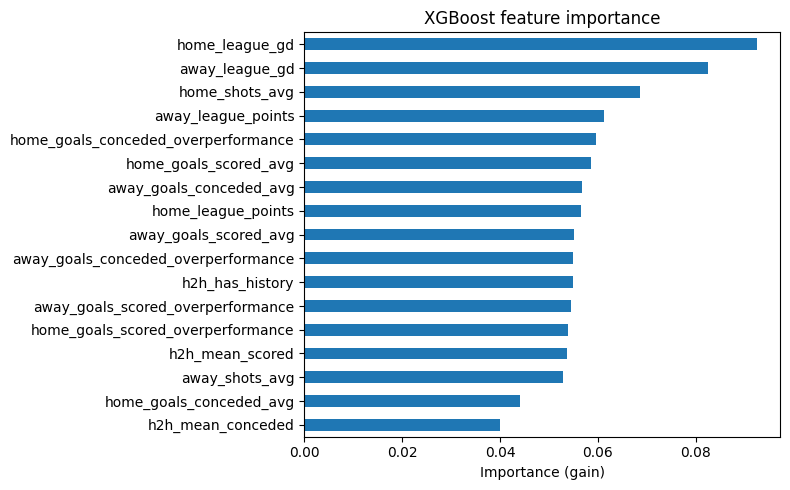

home_league_gd                         0.092566
away_league_gd                         0.082382
home_shots_avg                         0.068551
away_league_points                     0.061214
home_goals_conceded_overperformance    0.059508
home_goals_scored_avg                  0.058565
away_goals_conceded_avg                0.056791
home_league_points                     0.056564
away_goals_scored_avg                  0.055033
away_goals_conceded_overperformance    0.054887
h2h_has_history                        0.054818
away_goals_scored_overperformance      0.054419
home_goals_scored_overperformance      0.053946
h2h_mean_scored                        0.053748
away_shots_avg                         0.052804
home_goals_conceded_avg                0.044131
h2h_mean_conceded                      0.040074
dtype: float32


In [111]:
importances = pd.Series(
    model_home.feature_importances_, index=feature_cols
).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
importances.plot(kind="barh", ax=ax, color="tab:blue")
ax.set_xlabel("Importance (gain)")
ax.set_title("XGBoost feature importance")
plt.tight_layout()
plt.show()

print(importances.sort_values(ascending=False))

977.849 ConfidenceInterval(low=np.float64(908.0), high=np.float64(1049.05))
1108.0 857.0


(array([ 1.,  0.,  0.,  2.,  2.,  2.,  4.,  4.,  6.,  3.,  4., 11., 16.,
        13., 16., 35., 31., 45., 51., 37., 43., 52., 59., 67., 60., 58.,
        39., 55., 51., 40., 42., 36., 18., 18., 14., 13., 17.,  8.,  6.,
         3.,  5.,  4.,  2.,  1.,  1.,  3.,  1.,  0.,  0.,  1.]),
 array([ 857.  ,  862.02,  867.04,  872.06,  877.08,  882.1 ,  887.12,
         892.14,  897.16,  902.18,  907.2 ,  912.22,  917.24,  922.26,
         927.28,  932.3 ,  937.32,  942.34,  947.36,  952.38,  957.4 ,
         962.42,  967.44,  972.46,  977.48,  982.5 ,  987.52,  992.54,
         997.56, 1002.58, 1007.6 , 1012.62, 1017.64, 1022.66, 1027.68,
        1032.7 , 1037.72, 1042.74, 1047.76, 1052.78, 1057.8 , 1062.82,
        1067.84, 1072.86, 1077.88, 1082.9 , 1087.92, 1092.94, 1097.96,
        1102.98, 1108.  ]),
 <BarContainer object of 50 artists>)

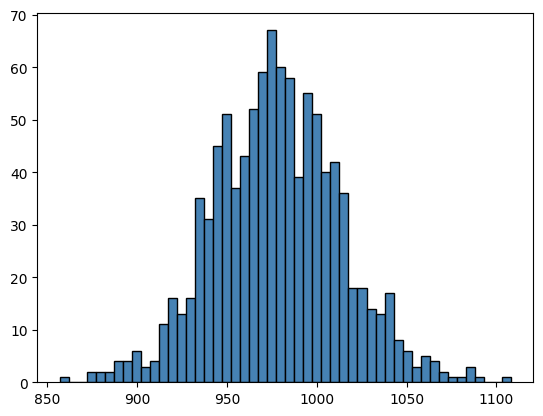

In [112]:
data = (results_df["points"].values.astype(float),)



def my_statistic(points_array):

    total_points = np.sum(points_array)
    return total_points

import scipy

result = scipy.stats.bootstrap(data, my_statistic, n_resamples=1000,
                                 confidence_level=0.95, method='percentile')

print(result.bootstrap_distribution.mean(), result.confidence_interval)
print(result.bootstrap_distribution.max(), result.bootstrap_distribution.min())

scipy.stats.mode(result.bootstrap_distribution)
plt.hist(result.bootstrap_distribution, bins = 50, color="steelblue", edgecolor="black")

In [113]:
results_df = score_predictions(test_df, df_model, model_home, model_away, feature_cols)

Matches predicted: 1484
Exact scores:      155 (10.4%)
Correct outcomes:  513 (34.6%)
Wrong:             816 (55.0%)
Total points:      978
Points per match:  0.66


980.352 ConfidenceInterval(low=np.float64(911.975), high=np.float64(1049.025))
1106.0 872.0


(array([ 2.,  2.,  2.,  2.,  2.,  3.,  4.,  4.,  7.,  8., 10., 21., 22.,
        25., 25., 29., 46., 48., 32., 59., 46., 46., 53., 49., 46., 51.,
        44., 54., 37., 42., 35., 18., 23., 19., 16., 22., 13.,  8.,  5.,
         3.,  5.,  3.,  1.,  0.,  3.,  3.,  1.,  0.,  0.,  1.]),
 array([ 872.  ,  876.68,  881.36,  886.04,  890.72,  895.4 ,  900.08,
         904.76,  909.44,  914.12,  918.8 ,  923.48,  928.16,  932.84,
         937.52,  942.2 ,  946.88,  951.56,  956.24,  960.92,  965.6 ,
         970.28,  974.96,  979.64,  984.32,  989.  ,  993.68,  998.36,
        1003.04, 1007.72, 1012.4 , 1017.08, 1021.76, 1026.44, 1031.12,
        1035.8 , 1040.48, 1045.16, 1049.84, 1054.52, 1059.2 , 1063.88,
        1068.56, 1073.24, 1077.92, 1082.6 , 1087.28, 1091.96, 1096.64,
        1101.32, 1106.  ]),
 <BarContainer object of 50 artists>)

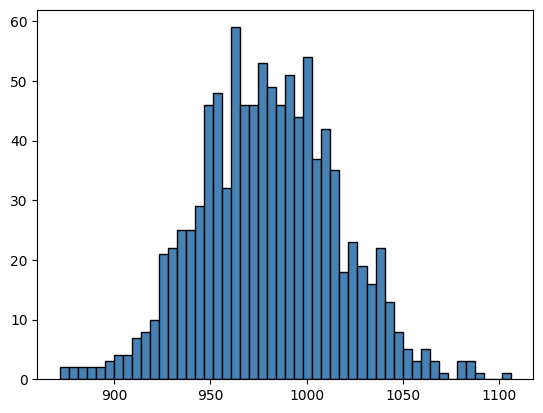

In [114]:
data = (results_df["points"].values.astype(float),)



def my_statistic(points_array):

    total_points = np.sum(points_array)
    return total_points

import scipy

result = scipy.stats.bootstrap(data, my_statistic, n_resamples=1000,
                                 confidence_level=0.95, method='percentile')

print(result.bootstrap_distribution.mean(), result.confidence_interval)
print(result.bootstrap_distribution.max(), result.bootstrap_distribution.min())

scipy.stats.mode(result.bootstrap_distribution)
plt.hist(result.bootstrap_distribution, bins = 50, color="steelblue", edgecolor="black")

In [120]:
from sklearn.model_selection import TimeSeriesSplit
from collections import Counter
import numpy as np

# Step 1: unique sorted match dates
unique_dates = np.sort(df_model["Date"].unique())

# Step 2: 5 chronological splits
tscv = TimeSeriesSplit(n_splits=5)

# Store results
fold_model_points = []
fold_baseline_points = []

fold_model_mae_home = []
fold_model_mae_away = []

# ---------------------------------------------------------
# Helper function: score predicted scorelines
# ---------------------------------------------------------

def calculate_points(pred_home, pred_away, actual_home, actual_away):

    if pred_home == actual_home and pred_away == actual_away:
        return 3

    elif (
        (pred_home > pred_away and actual_home > actual_away) or
        (pred_home == pred_away and actual_home == actual_away) or
        (pred_home < pred_away and actual_home < actual_away)
    ):
        return 1

    else:
        return 0


# ---------------------------------------------------------
# Backtesting
# ---------------------------------------------------------

for fold_num, (train_date_idx, test_date_idx) in enumerate(
    tscv.split(unique_dates), start=1
):

    # -----------------------------------------------------
    # 1. Get dates for this fold
    # -----------------------------------------------------

    train_dates = unique_dates[train_date_idx]
    test_dates = unique_dates[test_date_idx]

    train_mask = df_model["Date"].isin(train_dates)
    test_mask = df_model["Date"].isin(test_dates)

    fold_train = df_model[train_mask].copy()
    fold_test = df_model[test_mask].copy()

    # -----------------------------------------------------
    # 2. Training and test variables
    # -----------------------------------------------------

    X_train_fold = fold_train[feature_cols]
    y_train_home_fold = fold_train["FTHG"]
    y_train_away_fold = fold_train["FTAG"]

    X_test_fold = fold_test[feature_cols]
    y_test_home_fold = fold_test["FTHG"]
    y_test_away_fold = fold_test["FTAG"]

    # -----------------------------------------------------
    # 3. Train fresh models
    # -----------------------------------------------------

    model_home = xgb.XGBRegressor(
        objective="count:poisson",
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42
    )

    model_away = xgb.XGBRegressor(
        objective="count:poisson",
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42
    )

    model_home.fit(X_train_fold, y_train_home_fold)
    model_away.fit(X_train_fold, y_train_away_fold)

    # -----------------------------------------------------
    # 4. Model MAE
    # -----------------------------------------------------

    pred_home = model_home.predict(X_test_fold)
    pred_away = model_away.predict(X_test_fold)

    mae_h = mean_absolute_error(
        y_test_home_fold,
        pred_home
    )

    mae_a = mean_absolute_error(
        y_test_away_fold,
        pred_away
    )

    # -----------------------------------------------------
    # 5. MODEL: score each test match
    # -----------------------------------------------------

    model_results = score_predictions(
        fold_test,
        df_model,
        model_home,
        model_away,
        #cluster_labels,
        feature_cols
    )

    model_total_points = model_results["points"].sum()
    model_points_per_match = (
        model_total_points / len(model_results)
    )

    # -----------------------------------------------------
    # 6. BASELINE: best constant scoreline (by points) on training data
    # -----------------------------------------------------

    train_hg = fold_train["FTHG"].astype(int).values
    train_ag = fold_train["FTAG"].astype(int).values

    best_pts = -1
    for h in range(5):
        for a in range(5):
            pts = np.mean([
                calculate_points(h, a, x, y)
                for x, y in zip(train_hg, train_ag)
            ])
            if pts > best_pts:
                best_pts = pts
                baseline_home, baseline_away = h, a

    # 7. Score baseline predictions
    baseline_points = []

    for _, match in fold_test.iterrows():
        points = calculate_points(
            baseline_home,
            baseline_away,
            int(match["FTHG"]),
            int(match["FTAG"])
        )
        baseline_points.append(points)

    baseline_total_points = sum(baseline_points)
    baseline_points_per_match = baseline_total_points / len(fold_test)

    # 8. Store results
    fold_model_points.append(model_points_per_match)
    fold_baseline_points.append(baseline_points_per_match)

    fold_model_mae_home.append(mae_h)
    fold_model_mae_away.append(mae_a)
    # -----------------------------------------------------
    # 9. Print fold results
    # -----------------------------------------------------

    print(
        f"Fold {fold_num}: "
        f"{len(fold_train)} train, "
        f"{len(fold_test)} test | "
        f"Model = {model_points_per_match:.3f} | "
        f"Baseline = {baseline_points_per_match:.3f} | "
        f"Baseline score = {baseline_home}-{baseline_away} | "
        f"MAE home = {mae_h:.3f} | "
        f"MAE away = {mae_a:.3f}"
    )


# ---------------------------------------------------------
# 10. Overall results
# ---------------------------------------------------------

mean_model = np.mean(fold_model_points)
mean_baseline = np.mean(fold_baseline_points)

std_model = np.std(fold_model_points)
std_baseline = np.std(fold_baseline_points)

improvement = mean_model - mean_baseline

percentage_improvement = (
    improvement / mean_baseline * 100
    if mean_baseline > 0
    else np.nan
)

print("\n==============================")
print("BACKTEST SUMMARY")
print("==============================")

print(
    f"Model:     {mean_model:.3f} ± {std_model:.3f} points/match"
)

print(
    f"Baseline:  {mean_baseline:.3f} ± {std_baseline:.3f} points/match"
)

print(
    f"Difference: {improvement:+.3f} points/match"
)

print(
    f"Improvement: {percentage_improvement:+.1f}%"
)

print(
    f"\nMean MAE home: "
    f"{np.mean(fold_model_mae_home):.3f}"
)

print(
    f"Mean MAE away: "
    f"{np.mean(fold_model_mae_away):.3f}"
)

Matches predicted: 767
Exact scores:      71 (9.3%)
Correct outcomes:  270 (35.2%)
Wrong:             426 (55.5%)
Total points:      483
Points per match:  0.63
Fold 1: 839 train, 767 test | Model = 0.630 | Baseline = 0.572 | Baseline score = 2-1 | MAE home = 0.984 | MAE away = 0.943
Matches predicted: 820
Exact scores:      85 (10.4%)
Correct outcomes:  304 (37.1%)
Wrong:             431 (52.6%)
Total points:      559
Points per match:  0.68
Fold 2: 1606 train, 820 test | Model = 0.682 | Baseline = 0.629 | Baseline score = 1-0 | MAE home = 1.011 | MAE away = 0.849
Matches predicted: 766
Exact scores:      91 (11.9%)
Correct outcomes:  280 (36.6%)
Wrong:             395 (51.6%)
Total points:      553
Points per match:  0.72
Fold 3: 2426 train, 766 test | Model = 0.722 | Baseline = 0.655 | Baseline score = 2-1 | MAE home = 0.943 | MAE away = 0.806
Matches predicted: 766
Exact scores:      83 (10.8%)
Correct outcomes:  262 (34.2%)
Wrong:             421 (55.0%)
Total points:      511
Poi